# AgroShield: Base Model Notebook (CAT 2 / Project Deliverable 2)

**Team:** Moses Mugo (190027), Alfred Peter (190285), Duane Makedi (165767)

### How this notebook is organised (it follows the four CAT 2 tasks)
| Section | CAT 2 task | What it shows |
|---|---|---|
| 1 | Task 1 | The ML approach and algorithms, and why |
| 2 and 3 | Task 2 | Load, explore (EDA) and four observations |
| 4 | Task 2 | Data cleaning, step by step, to the final modelling dataset |
| 5 | Task 3 | The base model and the checks that prove the result is valid |
| 6 | Task 4 | Other models and other validation methods, compared |



The dataset used here (Kaggle *Ecommerce Counterfeit Products*) is one of the 5 datasets we have for our project used to demonstarte the marchine-learning workflow required for this CAT. It is has no pesticide data and contains no images. This notebook demonstrates the full machine-learning workflow that the real AgroShield engine will follow. 

## 0. Setup

In [1]:
# Libraries used in this notebook
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, GridSearchCV, learning_curve)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, RocCurveDisplay)

# Settings used everywhere, so that results can be reproduced
RANDOM_STATE = 42                                   # fixes all random choices
TARGET = "is_counterfeit"                           # the label the model must predict
DATA_FILE = "counterfeit_products.csv"              # same file as Deliverable 1

sns.set_theme(style="whitegrid")

## 1. ML approach and algorithms (Task 1)

**Problem type.** Each row is one product listing and the column `is_counterfeit` says whether it is counterfeit (True) or genuine (False). Because every example comes with the correct answer, this is **supervised learning**, and because the answer has two possible values it is **binary classification**.

**Expected output of the application.** For a new listing, the model returns *counterfeit* or *genuine* (with a probability). In AgroShield this is the idea of the "screening result" for a product.

**Candidate algorithms** (all suit supervised binary classification on mixed numeric and categorical data):

| Algorithm | Idea in one line | Why consider it |
|---|---|---|
| Logistic regression | Weighs each feature and turns the total into a probability | Simple, fast, easy to explain |
| Decision tree | Asks a series of yes/no questions | Very readable |
| **Random forest (base model)** | Many decision trees vote | Strong on tabular data, handles mixed features, gives feature importance |
| k-nearest neighbours | Looks at the most similar known listings | Intuitive, but needs scaled features |
| Gradient boosting | Trees built one after another, each fixing the last one's errors | Often the most accurate on tables |

**Base model chosen: Random forest** (confirmed in the shared group spreadsheet).

**Why the team chose it.** The data mix numeric features (price, seller rating, shipping time), yes/no flags and text categories, and a random forest handles all three without demanding a strict relationship between them. It averages many decorrelated trees, which makes it far less prone to overfitting than a single decision tree and gives stable results on a dataset of 5,000 rows. It also reports **feature importance**, so the team can explain which listing signals drive a "counterfeit" verdict. That explainability matters for AgroShield, where a farmer or agrovet must be told *why* a product looks suspicious. Finally, it needs little tuning and no feature scaling, so it is a dependable base model against which the other four algorithms can be compared.

**Metrics we will use** (accuracy alone can hide missed fakes): accuracy, precision, **recall of the counterfeit class**, F1, ROC-AUC and the confusion matrix. Recall matters most, because a missed counterfeit is the costly error.

## 2. Load the data

In [2]:
# Data loading. Works locally, or in Google Colab (it asks you to upload the CSV if it is not found).
candidates = [DATA_FILE, "ecommerce_dataset/" + DATA_FILE, "/content/" + DATA_FILE,
              "/content/ecommerce_dataset/" + DATA_FILE]
DATA_PATH = next((p for p in candidates if os.path.exists(p)), None)

if DATA_PATH is None:
    try:
        from google.colab import files          # only exists inside Colab
        print("Upload counterfeit_products.csv when prompted")
        files.upload()
        DATA_PATH = DATA_FILE
    except ImportError:
        raise FileNotFoundError("counterfeit_products.csv not found. Place it next to this notebook.")

print("Using file:", DATA_PATH)

Using file: counterfeit_products.csv


In [3]:
# Load the same file explored in Deliverable 1
df_raw = pd.read_csv(DATA_PATH)

# Work on a copy so that the raw data is never changed
df = df_raw.copy()

print("Rows, columns:", df.shape)
df.head()

Rows, columns: (5000, 27)


,product_id,seller_id,category,brand,price,seller_rating,seller_reviews,product_images,description_length,shipping_time_days,...,shipping_origin,views,purchases,wishlist_adds,certification_badges,warranty_months,bulk_orders,unusual_payment_patterns,ip_location_mismatch,is_counterfeit
0,dcb12716,seller_5426,Electronics,DigitalPro,218.54,4.9,5291,7,220,7,...,JP,3454,99,23,2,21,True,False,True,False
1,d1f8b777,seller_4385,Luxury Goods,TechCrop,20.72,3.2,29,2,179,41,...,CA,4127,252,88,0,9,False,False,False,True
2,9989f13a,seller_2528,Fashion,FashionForward,18.87,3.9,14,2,100,25,...,CN,3212,306,6,4,8,True,True,False,True
3,4e008120,seller_8099,Electronics,CircuitMaster,79.27,4.9,8533,4,976,10,...,CN,1488,7,46,2,13,False,False,False,False
4,933b65ba,seller_7873,Luxury Goods,PremiumCraft,225.98,3.8,7655,4,589,6,...,DE,171,9,5,3,13,False,False,False,False


In [4]:
# Data types of each column
df.dtypes

product_id                      str
seller_id                       str
category                        str
brand                           str
price                       float64
seller_rating               float64
seller_reviews                int64
product_images                int64
description_length            int64
shipping_time_days            int64
spelling_errors               int64
domain_age_days               int64
contact_info_complete          bool
return_policy_clear            bool
payment_methods_count         int64
listing_date                    str
seller_country                  str
shipping_origin                 str
views                         int64
purchases                     int64
wishlist_adds                 int64
certification_badges          int64
warranty_months               int64
bulk_orders                    bool
unusual_payment_patterns       bool
ip_location_mismatch           bool
is_counterfeit                 bool
dtype: object

## 3. Exploratory data analysis (EDA) (Task 2, part 1)

Each cell below asks one question. The four observations drawn from the results are in section 3.7.

### 3.1 Is the target balanced?

is_counterfeit
False    3530
True     1470
Name: count, dtype: int64

is_counterfeit
False    0.706
True     0.294
Name: proportion, dtype: float64


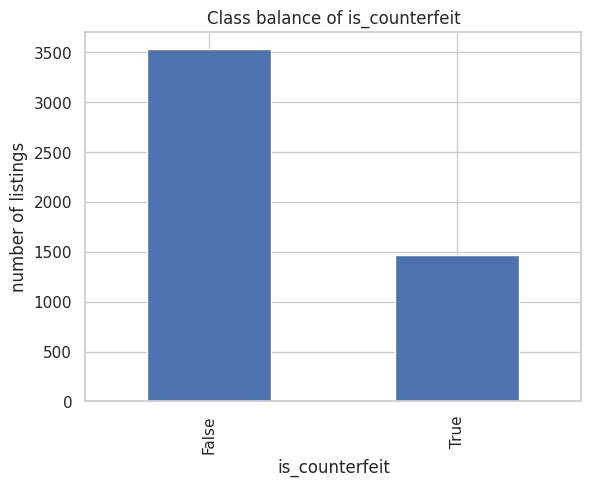

In [5]:
# How many counterfeit and genuine listings are there?
counts = df[TARGET].value_counts()
print(counts)
print()
print(df[TARGET].value_counts(normalize=True).round(3))

counts.plot(kind="bar", title="Class balance of is_counterfeit")
plt.xlabel("is_counterfeit"); plt.ylabel("number of listings")
plt.show()

### 3.2 Missing values and duplicates

In [6]:
# Missing values per column (only show columns that have some)
missing = df.isnull().sum()
print("Columns with missing values:")
print(missing[missing > 0] if (missing > 0).any() else "None")

# Exact duplicate rows, and repeated product IDs
print("\nDuplicate rows:", df.duplicated().sum())
print("Repeated product_id values:", df["product_id"].duplicated().sum())
print("Number of distinct sellers:", df["seller_id"].nunique(), "for", len(df), "rows")

Columns with missing values:
None

Duplicate rows: 0
Repeated product_id values: 0
Number of distinct sellers: 3828 for 5000 rows


### 3.3 Do counterfeit and genuine listings differ on the numeric features?

In [7]:
# Average of each numeric feature for genuine (False) vs counterfeit (True)
num_cols_eda = df.select_dtypes(include="number").columns
df.groupby(TARGET)[num_cols_eda].mean().T.round(2)

is_counterfeit,False,True
price,275.76,102.65
seller_rating,4.25,2.48
seller_reviews,4978.50,50.97
product_images,6.01,1.51
description_length,604.37,125.45
shipping_time_days,7.00,28.98
spelling_errors,0.51,2.49
domain_age_days,1985.83,184.04
payment_methods_count,3.99,1.48
views,2465.11,2479.31


In [8]:
# Spread of the numeric features (min, quartiles, max) to spot unusual values
df[num_cols_eda].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
price,5000.0,224.87,136.74,10.12,109.79,191.82,336.62,499.84
seller_rating,5000.0,3.73,1.00,1.00,3.50,4.00,4.50,5.00
seller_reviews,5000.0,3529.81,3281.42,0.00,85.00,2922.50,6401.50,9996.00
product_images,5000.0,4.69,2.65,1.00,2.00,5.00,7.00,9.00
description_length,5000.0,463.56,294.29,50.00,179.00,433.50,725.25,999.00
shipping_time_days,5000.0,13.46,11.55,1.00,5.00,10.00,18.00,44.00
spelling_errors,5000.0,1.09,1.16,0.00,0.00,1.00,1.00,4.00
domain_age_days,5000.0,1456.11,1143.26,1.00,307.50,1319.00,2465.00,3649.00
payment_methods_count,5000.0,3.25,1.36,1.00,2.00,3.00,4.00,5.00
views,5000.0,2469.29,1424.53,10.00,1245.75,2433.00,3701.50,4996.00


### 3.4 Categories and brands

In [9]:
# Share of counterfeit listings within each product category
df.groupby("category")[TARGET].mean().sort_values().round(3)

category
Luxury Goods        0.274
Pharmaceuticals     0.281
Fashion             0.287
Cosmetics           0.292
Automotive Parts    0.311
Electronics         0.319
Name: is_counterfeit, dtype: float64

In [10]:
# How messy are the brand names? Compare distinct raw names with the most common ones
print("Distinct brand values:", df["brand"].nunique())
df["brand"].value_counts().head(40)

Distinct brand values: 36


brand
LuxuryBrand         200
HealthCare Plus     181
AutoParts Pro       180
CircuitMaster       176
ExclusiveItems      176
PureSkin            174
CarTech             171
PremiumCraft        170
ElectroMax          169
ClassicWear         168
MediPharm           168
BeautyLux           167
WellnessLab         167
BioMed Solutions    161
FashionForward      157
EliteDesign         155
MotorMax            154
NaturalGlow         154
TrendSetter         149
TechCorp            148
DigitalPro          147
VehicleCare         147
GlamourCo           145
StyleHouse          135
DigitalPr0          105
GlamourC0            97
StyleHous            97
PureSk1n             96
CircuitMastr         96
ClassicWear.         94
TechCrop             91
TrendSettr           86
FashionForward_      85
BeautyLu×            82
NaturalGl0w          76
ElectroMx            76
Name: count, dtype: int64

### 3.5 True/False flag columns versus the label

In [11]:
# For each True/False feature, what share of listings is counterfeit when the flag is False vs True?
flag_cols = [c for c in df.select_dtypes(include="bool").columns if c != TARGET]
for c in flag_cols:
    print(c)
    print(df.groupby(c)[TARGET].mean().round(3).to_string())
    print()

contact_info_complete
contact_info_complete
False    0.732
True     0.127

return_policy_clear
return_policy_clear
False    0.564
True     0.174

bulk_orders
bulk_orders
False    0.288
True     0.319

unusual_payment_patterns
unusual_payment_patterns
False    0.293
True     0.303

ip_location_mismatch
ip_location_mismatch
False    0.291
True     0.311



### 3.6 Which numeric features move with the label?

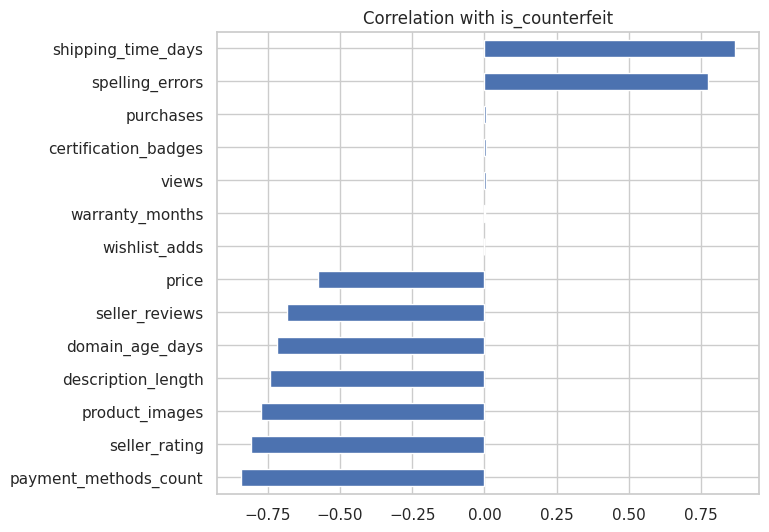

payment_methods_count   -0.842
seller_rating           -0.810
product_images          -0.773
description_length      -0.741
domain_age_days         -0.718
seller_reviews          -0.684
price                   -0.577
wishlist_adds           -0.002
warranty_months          0.001
views                    0.005
certification_badges     0.006
purchases                0.006
spelling_errors          0.774
shipping_time_days       0.867
Name: target, dtype: float64

In [12]:
# Correlation of each numeric feature with the target (sign shows direction)
corr_with_target = (df[num_cols_eda]
                    .assign(target=df[TARGET].astype(int))
                    .corr()["target"].drop("target")
                    .sort_values())
corr_with_target.plot(kind="barh", title="Correlation with is_counterfeit", figsize=(7, 6))
plt.show()
corr_with_target.round(3)

### 3.7 Observations from the EDA

1. **Class balance.** 1,470 of the 5,000 listings (29.4%) are counterfeit and 3,530 (70.6%) are genuine. The classes are moderately imbalanced, so accuracy alone would be misleading: a model that always answers "genuine" is right 70.6% of the time while catching no fakes. We therefore report recall, precision, F1 and ROC-AUC, split the data with `stratify`, and keep the counterfeit share equal in train and test.
2. **Data quality.** There are no missing values, no duplicate rows and no repeated `product_id`. The 5,000 listings come from 3,828 distinct sellers (at most 5 listings each), so seller IDs are nearly one-off labels with no use to a model and are dropped. The real quality problem is in the text columns (observation 4), not in missing data. We still keep imputers in the pipeline as a safeguard for new data.
3. **Features that separate the classes.** Counterfeit listings differ sharply from genuine ones: average shipping time 28.98 vs 7.00 days, seller reviews 51 vs 4,979, description length 125 vs 604 characters, domain age 184 vs 1,986 days, and 1.5 vs 6.0 product images. Correlations with the label reach +0.87 (shipping time) and -0.84 (payment methods). Several features are strong signals, so a model should be able to learn this problem easily.
4. **Brand names.** There are 36 distinct brand spellings for only 24 real brands, with look-alike characters (`DigitalPr0`, `BeautyLu×`), stray symbols (`ClassicWear.`, `FashionForward_`) and dropped letters (`StyleHous`). 1,081 listings (21.6%) use a non-official spelling and **all** of them are counterfeit, against 9.9% counterfeit among official spellings. The spelling itself is therefore a signal and must be kept as a feature before the names are repaired.
5. **Features with no signal.** Views, purchases, wishlist adds, certification badges and warranty months have correlations with the label between -0.002 and +0.006, and `bulk_orders`, `unusual_payment_patterns` and `ip_location_mismatch` give about the same counterfeit share whether True or False (28.8 to 31.9%). Category differences are small (27.4% to 31.9%). Fraud indicators that should matter in real life show nothing here, which is the first hint that the data are artificial (discussed in section 5.7). By contrast `contact_info_complete` False vs True gives 73.2% vs 12.7% counterfeit, and `return_policy_clear` False vs True gives 56.4% vs 17.4%.

## 4. Data cleaning: from exploration to the final modelling dataset (Task 2, part 2)

Every step below is logged in `cleaning_log` so the notebook shows how many rows and columns remain after each step. For each step, the markdown above the cell explains **what** is done and **why**.

In [13]:
# A small log that records the size of the data after every cleaning step
cleaning_log = []
def log_step(name, data):
    cleaning_log.append({"step": name, "rows": data.shape[0], "columns": data.shape[1]})

log_step("0. Raw data loaded", df)

### 4.1 Remove duplicate rows
**Why:** identical rows give the model the same example twice, and if one copy lands in training and one in testing the test score is inflated.

In [14]:
n_before = len(df)
df = df.drop_duplicates()
print("Rows removed:", n_before - len(df))
log_step("1. Duplicate rows removed", df)

Rows removed: 0


### 4.2 Clean the brand names
**Why:** the same brand appears with look-alike characters (for example `DigitalPr0` or `BeautyLu×`) and with dropped or swapped letters (for example `StyleHous` or `TechCrop`). Left alone, the model would treat each spelling as a different brand. We (a) record **whether the raw name is anything other than an official spelling**, because that may itself be a sign of a fake listing, then (b) map look-alike characters back to letters, and (c) merge the remaining near-miss spellings onto the official name.

An *official* spelling is one that appears at least 120 times (a clear gap separates these 24 names from the variants, which all appear fewer than 105 times).

In [15]:
# (a) Flags: odd characters in the raw name, and "not one of the official spellings"
vc = df["brand"].value_counts()
official = vc[vc >= 120].index.tolist()
print("Official brand spellings found:", len(official))

df["brand_has_odd_chars"] = df["brand"].str.contains(r"[^A-Za-z ]", regex=True).astype(int)
df["brand_misspelled"] = (~df["brand"].isin(official)).astype(int)   # includes the odd-character cases

Official brand spellings found: 24


In [16]:
# (b) Replace look-alike characters, strip leftover symbols, lower-case
import difflib
lookalikes = str.maketrans({"0": "o", "1": "l", "3": "e", "4": "a",
                            "5": "s", "\u00d7": "x", "$": "s", "@": "a"})
step_b = (df["brand"].str.translate(lookalikes)
                     .str.replace(r"[^A-Za-z ]", "", regex=True)
                     .str.strip().str.lower())

# (c) Merge near-miss spellings (dropped/swapped letters) onto the closest official name
official_lc = [o.lower() for o in official]
def to_official(name):
    match = difflib.get_close_matches(name, official_lc, n=1, cutoff=0.8)
    return match[0] if match else name
df["brand_clean"] = step_b.map(to_official)

print("Distinct brands before cleaning :", df["brand"].nunique())
print("After look-alike fix only (b)   :", step_b.nunique())
print("After near-miss merge (b + c)   :", df["brand_clean"].nunique())
df[["brand", "brand_clean", "brand_has_odd_chars", "brand_misspelled"]].sample(8, random_state=RANDOM_STATE)

Distinct brands before cleaning : 36
After look-alike fix only (b)   : 30
After near-miss merge (b + c)   : 24


,brand,brand_clean,brand_has_odd_chars,brand_misspelled
1501,NaturalGlow,naturalglow,0,0
2586,DigitalPro,digitalpro,0,0
2653,CarTech,cartech,0,0
1055,TrendSetter,trendsetter,0,0
705,HealthCare Plus,healthcare plus,0,0
106,PureSk1n,pureskin,1,1
589,GlamourCo,glamourco,0,0
2468,CircuitMastr,circuitmaster,0,1


In [17]:
# Do the two brand flags relate to the label? (used in our observations)
print(df.groupby("brand_has_odd_chars")[TARGET].agg(["mean", "size"]).round(3))
print()
print(df.groupby("brand_misspelled")[TARGET].agg(["mean", "size"]).round(3))

                      mean  size
brand_has_odd_chars             
0                    0.191  4365
1                    1.000   635

                   mean  size
brand_misspelled             
0                 0.099  3919
1                 1.000  1081


In [18]:
log_step("2. Brand names cleaned, two spelling flags added", df)

### 4.3 Turn the listing date into useful numbers
**Why:** a model cannot use a date stored as text. We convert it and keep month and day of week. Dates that cannot be read become missing and are handled later.

In [19]:
df["listing_date"] = pd.to_datetime(df["listing_date"], errors="coerce")
print("Dates that could not be read:", df["listing_date"].isna().sum())

df["listing_month"] = df["listing_date"].dt.month
df["listing_dayofweek"] = df["listing_date"].dt.dayofweek
log_step("3. Date converted to month and day of week", df)

Dates that could not be read: 0


### 4.4 Drop columns that should not be learned from
**Why:** `product_id` and `seller_id` are labels for a row, not properties of the product. A model could memorise them and fail on new listings. The raw `listing_date` and raw `brand` are replaced by the cleaned versions above.

In [20]:
df = df.drop(columns=["product_id", "seller_id", "listing_date", "brand"])
log_step("4. Identifier and replaced columns dropped", df)

### 4.5 Convert True/False columns to 0/1
**Why:** models work with numbers.

In [21]:
for c in df.select_dtypes(include="bool").columns:
    df[c] = df[c].astype(int)
log_step("5. True/False columns converted to 0/1", df)
df.dtypes

category                        str
price                       float64
seller_rating               float64
seller_reviews                int64
product_images                int64
description_length            int64
shipping_time_days            int64
spelling_errors               int64
domain_age_days               int64
contact_info_complete         int64
return_policy_clear           int64
payment_methods_count         int64
seller_country                  str
shipping_origin                 str
views                         int64
purchases                     int64
wishlist_adds                 int64
certification_badges          int64
warranty_months               int64
bulk_orders                   int64
unusual_payment_patterns      int64
ip_location_mismatch          int64
is_counterfeit                int64
brand_has_odd_chars           int64
brand_misspelled              int64
brand_clean                     str
listing_month                 int32
listing_dayofweek           

### 4.6 Check for outliers
**Why:** extreme values can distort some models. We count values outside 1.5 x IQR for each **measured** numeric column and then decide, rather than deleting automatically. The 0/1 flags and the calendar features (month, day of week) are left out because they only take a few fixed values, so "outlier" has no meaning for them.

In [22]:
# Only genuinely measured columns: not the target, not 0/1 flags, not calendar codes
calendar_cols = ["listing_month", "listing_dayofweek"]
measured = [c for c in df.select_dtypes(include="number").columns
            if c != TARGET and df[c].nunique() > 2 and c not in calendar_cols]

rows = []
for c in measured:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[c] < low) | (df[c] > high)).sum()
    rows.append({"feature": c, "min": df[c].min(), "max": df[c].max(),
                 "outliers": n_out, "share_%": round(100 * n_out / len(df), 2)})
outlier_table = pd.DataFrame(rows).sort_values("outliers", ascending=False)
outlier_table

,feature,min,max,outliers,share_%
6,spelling_errors,0.00,4.00,726,14.52
1,seller_rating,1.00,5.00,470,9.40
5,shipping_time_days,1.00,44.00,322,6.44
10,purchases,0.00,491.00,85,1.70
0,price,10.12,499.84,0,0.00
2,seller_reviews,0.00,9996.00,0,0.00
4,description_length,50.00,999.00,0,0.00
3,product_images,1.00,9.00,0,0.00
8,payment_methods_count,1.00,5.00,0,0.00
7,domain_age_days,1.00,3649.00,0,0.00


In [23]:
# Check for impossible values (these, unlike outliers, would be errors)
print("Negative prices          :", (df["price"] < 0).sum())
print("Ratings outside 0 to 5   :", ((df["seller_rating"] < 0) | (df["seller_rating"] > 5)).sum())
print("Negative counts or days  :", (df[["seller_reviews", "product_images", "shipping_time_days",
                                          "domain_age_days", "views", "purchases"]] < 0).sum().sum())

Negative prices          : 0
Ratings outside 0 to 5   : 0
Negative counts or days  : 0


**Decision.** We keep every row. No value is impossible: there are no negative prices, no ratings outside 0 to 5 and no negative counts. Four columns have values outside the 1.5 x IQR fences, and in each case they are valid, in-range values rather than errors:

- `spelling_errors` (726 flagged, 14.5%): the values 3 and 4. Every one of these listings is counterfeit. Because the usual number of errors is 0 or 1, the fence sits at 2.5 and anything higher is flagged.
- `seller_rating` (470, 9.4%): ratings below 2.0, all counterfeit. The ratings are bounded between 1 and 5.
- `shipping_time_days` (322, 6.4%): 38 to 44 days, all counterfeit.
- `purchases` (85, 1.7%): 412 to 491, a mix of both classes (34% counterfeit) and a feature with no link to the label.

These "outliers" are largely the counterfeit listings themselves, so deleting them would remove the very signal the model must learn. Tree-based models are not sensitive to extreme values, and the scaling step limits their effect on logistic regression and k-nearest neighbours. We do not delete data without a reason.

### 4.7 Separate features from the label, then split **before** any learning from the data
**Why:** the test set must stay unseen. If we scaled or encoded using all the data first, information from the test set would leak into training. So we split first. `stratify=y` keeps the same counterfeit share in both parts.

In [24]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("Training set:", X_train.shape, "| Test set:", X_test.shape)
print("Counterfeit share  train:", round(y_train.mean(), 3), " test:", round(y_test.mean(), 3))
log_step("6. Split into train (80%) and test (20%)", X_train)

Training set: (4000, 27) | Test set: (1000, 27)
Counterfeit share  train: 0.294  test: 0.294


### 4.8 Missing values, scaling and encoding (fitted on the training data only)
**Why:** text columns (category, brand, countries) must become numbers, and numeric columns are put on a common scale so that distance-based models are not dominated by large values. We build one **preprocessor** and reuse it for every model so that comparisons are fair. Rare categories (under 1% of rows) are grouped together, and unseen categories at test time are ignored instead of causing an error.

| Column type | Missing values | Then |
|---|---|---|
| Numeric | filled with the median | standardised (mean 0, spread 1) |
| Categorical | filled with the most common value | one-hot encoded |

In [25]:
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()   # text columns
num_cols = X_train.select_dtypes(include="number").columns.tolist()   # numeric (incl. 0/1 flags)
print("Categorical:", cat_cols)
print("Numeric    :", num_cols)

numeric_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                         ("scale", StandardScaler())])
categorical_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                             ("onehot", OneHotEncoder(handle_unknown="ignore",
                                                      min_frequency=0.01,
                                                      sparse_output=False))])

preprocessor = ColumnTransformer([("num", numeric_pipe, num_cols),
                                  ("cat", categorical_pipe, cat_cols)])

# Fit on the training data only, then look at the final modelling dataset
X_train_ready = preprocessor.fit_transform(X_train)
print("\nFinal modelling matrix (training):", X_train_ready.shape)
print("First 10 feature names:", list(preprocessor.get_feature_names_out()[:10]))

Categorical: ['category', 'seller_country', 'shipping_origin', 'brand_clean']
Numeric    : ['price', 'seller_rating', 'seller_reviews', 'product_images', 'description_length', 'shipping_time_days', 'spelling_errors', 'domain_age_days', 'contact_info_complete', 'return_policy_clear', 'payment_methods_count', 'views', 'purchases', 'wishlist_adds', 'certification_badges', 'warranty_months', 'bulk_orders', 'unusual_payment_patterns', 'ip_location_mismatch', 'brand_has_odd_chars', 'brand_misspelled', 'listing_month', 'listing_dayofweek']

Final modelling matrix (training): (4000, 73)
First 10 feature names: ['num__price', 'num__seller_rating', 'num__seller_reviews', 'num__product_images', 'num__description_length', 'num__shipping_time_days', 'num__spelling_errors', 'num__domain_age_days', 'num__contact_info_complete', 'num__return_policy_clear']


In [26]:
# Summary of the whole cleaning journey (put this table in your presentation)
log_step("7. After encoding (training matrix)", pd.DataFrame(X_train_ready))
pd.DataFrame(cleaning_log)

,step,rows,columns
0,0. Raw data loaded,5000,27
1,1. Duplicate rows removed,5000,27
2,"2. Brand names cleaned, two spelling flags added",5000,30
3,3. Date converted to month and day of week,5000,32
4,4. Identifier and replaced columns dropped,5000,28
5,5. True/False columns converted to 0/1,5000,28
6,6. Split into train (80%) and test (20%),4000,27
7,7. After encoding (training matrix),4000,73


## 5. The base model: Random forest (Task 3)

We describe the modelling approach, then apply measures to **verify that the result is valid**, as the CAT asks.

**Approach:** preprocessor + random forest in a single *pipeline*, so every step is learned from the training data only. The forest uses 200 trees.

In [27]:
def make_pipe(clf):
    # A fresh copy of the preprocessor + the chosen classifier
    return Pipeline([("prep", clone(preprocessor)), ("clf", clf)])

base_model = make_pipe(RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))
base_model.fit(X_train, y_train)

y_pred = base_model.predict(X_test)
y_prob = base_model.predict_proba(X_test)[:, 1]
print("Base model fitted.")

Base model fitted.


### 5.1 Performance on the unseen test set

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0  <- share of counterfeits caught
F1       : 1.0
ROC-AUC  : 1.0

              precision    recall  f1-score   support

     genuine       1.00      1.00      1.00       706
 counterfeit       1.00      1.00      1.00       294

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



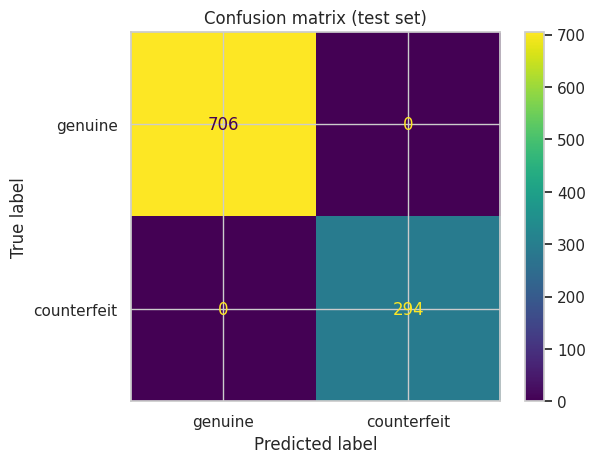

In [28]:
print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall   :", round(recall_score(y_test, y_pred), 3), " <- share of counterfeits caught")
print("F1       :", round(f1_score(y_test, y_pred), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 3))
print()
print(classification_report(y_test, y_pred, target_names=["genuine", "counterfeit"]))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["genuine", "counterfeit"])
plt.title("Confusion matrix (test set)")
plt.show()

**How to read the confusion matrix.** The cell where the true label is *counterfeit* and the prediction is *genuine* is the **missed fake** (a false negative), the costliest error in this project.

**Result.** The base model missed **0 of the 294 counterfeit listings** in the test set and wrongly flagged **0 of the 706 genuine listings**. Every score (accuracy, precision, recall, F1, ROC-AUC) is 1.00. Perfect scores need explaining rather than celebrating, and the checks below do that.

### 5.2 Validity measure 1: compare with a "no-skill" model
**Why:** if 70% of listings are genuine, a model that always says "genuine" scores 70% without learning anything. Our model must beat that.

In [29]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
print("Always-predict-majority  accuracy:", round(accuracy_score(y_test, dummy_pred), 3),
      "| recall:", round(recall_score(y_test, dummy_pred, zero_division=0), 3))
print("Random forest            accuracy:", round(accuracy_score(y_test, y_pred), 3),
      "| recall:", round(recall_score(y_test, y_pred), 3))

Always-predict-majority  accuracy: 0.706 | recall: 0.0
Random forest            accuracy: 1.0 | recall: 1.0


**Result.** The no-skill model reaches 70.6% accuracy but recall of 0.0, so it finds no counterfeits at all. The random forest scores 100% on both. The forest clearly beats the baseline, by 29.4 percentage points of accuracy and by the whole of the recall gap.

### 5.3 Validity measure 2: check for overfitting
**Why:** a model that memorises the training data scores very high there and much lower on new data. A big gap is the warning sign.

In [30]:
train_acc = accuracy_score(y_train, base_model.predict(X_train))
test_acc = accuracy_score(y_test, y_pred)
print("Training accuracy:", round(train_acc, 3))
print("Test accuracy    :", round(test_acc, 3))
print("Gap              :", round(train_acc - test_acc, 3))

Training accuracy: 1.0
Test accuracy    : 1.0
Gap              : 0.0


**Result.** Training accuracy is 1.000, test accuracy is 1.000 and the gap is 0.000. A gap is the warning sign of memorising, and there is none here: the model does equally well on listings it has never seen. A perfect training score alone would not be a problem for a random forest, which can fit its own training data almost exactly. What matters is that the test score is equal, so the model is not overfitted in the usual sense. The more likely reason for the perfect scores is that the problem itself is very easy (section 5.7).

### 5.4 Validity measure 3: stratified 5-fold cross-validation
**Why:** one train/test split could be lucky or unlucky. Cross-validation splits the **training data** into 5 parts, trains on 4 and tests on the 5th, and rotates. If the five scores are close together, the result is stable. The test set is not touched here.

In [31]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

cv_res = cross_validate(base_model, X_train, y_train, cv=cv, scoring=scoring,
                        return_train_score=True, n_jobs=-1)

cv_table = pd.DataFrame({
    "metric": scoring,
    "mean_validation": [cv_res[f"test_{m}"].mean() for m in scoring],
    "std_validation": [cv_res[f"test_{m}"].std() for m in scoring],
    "mean_train": [cv_res[f"train_{m}"].mean() for m in scoring],
}).round(3)
cv_table

,metric,mean_validation,std_validation,mean_train
0,accuracy,1.0,0.0,1.0
1,precision,1.0,0.0,1.0
2,recall,1.0,0.0,1.0
3,f1,1.0,0.0,1.0
4,roc_auc,1.0,0.0,1.0


In [32]:
# The five fold scores for F1, to see the spread directly
print("F1 per fold:", cv_res["test_f1"].round(3))

F1 per fold: [1. 1. 1. 1. 1.]


**Result.** All five folds give F1 = 1.000 and the standard deviation of every metric is 0.000. The cross-validated scores match the test-set scores in 5.1 exactly, so the single test result was not a fluke of one lucky split, and the model is perfectly stable across different slices of the training data. Training and validation scores are also identical.

> **Why we are cautious rather than proud.** Zero variation across folds and a perfect score on every metric is not normal for real-world data. Real listings are messy, and genuine and counterfeit examples overlap. A result like this usually means the label follows simple rules that any model can find. Section 5.7 tests that explanation directly.

### 5.5 Tune the forest with cross-validation
**Why:** settings such as tree depth change performance. `GridSearchCV` tries a small grid with cross-validation, using the training data only. The tuned forest is then scored **once** on the test set and compared with the base forest, so the tuning has to earn its place.

In [33]:
param_grid = {"clf__max_depth": [None, 10, 20],
              "clf__min_samples_leaf": [1, 5],
              "clf__max_features": ["sqrt", 0.5]}

grid = GridSearchCV(base_model, param_grid, cv=cv, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best settings:", grid.best_params_)
print("Best cross-validated F1:", round(grid.best_score_, 3))
print("Base model cross-validated F1:", round(cv_res["test_f1"].mean(), 3))

Best settings: {'clf__max_depth': None, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 1}
Best cross-validated F1: 1.0
Base model cross-validated F1: 1.0


In [34]:
# Score the tuned forest once on the unseen test set and compare with the base forest
tuned_model = grid.best_estimator_
tuned_pred = tuned_model.predict(X_test)
tuned_prob = tuned_model.predict_proba(X_test)[:, 1]

def test_scores(pred, prob):
    return {"accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred),
            "recall": recall_score(y_test, pred), "f1": f1_score(y_test, pred),
            "roc_auc": roc_auc_score(y_test, prob),
            "missed_fakes": int(((y_test == 1) & (pred == 0)).sum())}

pd.DataFrame({"Base forest": test_scores(y_pred, y_prob),
              "Tuned forest": test_scores(tuned_pred, tuned_prob)}).T.round(3)

,accuracy,precision,recall,f1,roc_auc,missed_fakes
Base forest,1.0,1.0,1.0,1.0,1.0,0.0
Tuned forest,1.0,1.0,1.0,1.0,1.0,0.0


**Result.** The grid search chose the default settings (`max_depth=None`, `min_samples_leaf=1`, `max_features="sqrt"`), with a cross-validated F1 of 1.000, the same as the base model. On the test set the tuned and base forests are identical (every metric 1.000, 0 missed fakes). Tuning therefore gives no improvement here and we **keep the base forest as the final model**. This is a useful finding in itself: the base settings are already at the ceiling, so there is nothing left for tuning to fix. On harder data, such as the real AgroShield image data, tuning is expected to matter.

### 5.6 What did the model learn? Feature importance
**Why:** shows which features drive the predictions and helps spot features that look suspiciously perfect.

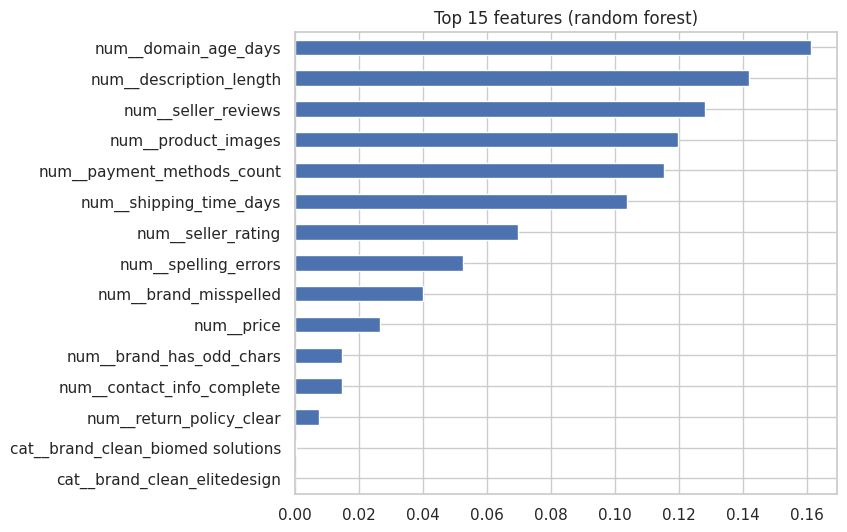

num__domain_age_days                 0.161
num__description_length              0.142
num__seller_reviews                  0.128
num__product_images                  0.120
num__payment_methods_count           0.115
num__shipping_time_days              0.104
num__seller_rating                   0.070
num__spelling_errors                 0.053
num__brand_misspelled                0.040
num__price                           0.027
num__brand_has_odd_chars             0.015
num__contact_info_complete           0.015
num__return_policy_clear             0.008
cat__brand_clean_biomed solutions    0.000
cat__brand_clean_elitedesign         0.000
dtype: float64

In [35]:
rf = base_model.named_steps["clf"]
feature_names = base_model.named_steps["prep"].get_feature_names_out()
importances = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False)

importances.head(15).sort_values().plot(kind="barh", figsize=(7, 6),
                                        title="Top 15 features (random forest)")
plt.show()
importances.head(15).round(3)

**Interpretation.** The top three features are `domain_age_days` (0.161), `description_length` (0.142) and `seller_reviews` (0.128), followed by `product_images`, `payment_methods_count` and `shipping_time_days`. These make sense: a counterfeit seller tends to run a very new website (184 days on average vs 1,986), write short descriptions, and have few reviews, few photos and few payment options. They match our EDA observation 3, where the same features showed the biggest differences between the classes. The two brand-spelling flags we engineered also appear in the top 15 (`brand_misspelled` 0.040, `brand_has_odd_chars` 0.015), confirming observation 4. The no-signal features from observation 5 (views, purchases, wishlist adds, badges, warranty) carry almost no importance, as expected.

Importance is spread across six or seven features of similar size. This is typical when several features each separate the classes fully and the forest shares the credit between them.

### 5.7 Sanity check: how hard is this problem really?
**Why:** perfect scores are a reason to look closer, not to celebrate. Two quick checks: (1) the smallest and largest value of key features in each class, to see whether the classes overlap at all, and (2) how well a **single yes/no question** on one feature does (a decision tree of depth 1, scored with cross-validation on the training data).

In [36]:
# (1) Do the two classes overlap on the key features?
key = ["shipping_time_days", "description_length", "seller_reviews",
       "domain_age_days", "product_images", "payment_methods_count"]
ranges = X_train[key].groupby(y_train.map({0: "genuine", 1: "counterfeit"})).agg(["min", "max"]).T
ranges

is_counterfeit             counterfeit  genuine
shipping_time_days    min           14        1
                      max           44       13
description_length    min           50      200
                      max          199      999
seller_reviews        min            0      100
                      max           99     9996
domain_age_days       min            1      365
                      max          364     3649
product_images        min            1        3
                      max            2        9
payment_methods_count min            1        3
                      max            2        5

In [37]:
# (2) One-question model per feature: a depth-1 tree on a single column
stump_rows = []
for c in ["price", "seller_rating", "spelling_errors"] + key:
    f1s = cross_validate(DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE),
                         X_train[[c]], y_train, cv=cv, scoring="f1")["test_score"]
    stump_rows.append({"single feature": c, "cross-validated F1": f1s.mean()})
pd.DataFrame(stump_rows).sort_values("cross-validated F1", ascending=False).round(3)

,single feature,cross-validated F1
4,description_length,1.000
7,product_images,1.000
3,shipping_time_days,1.000
8,payment_methods_count,1.000
6,domain_age_days,1.000
5,seller_reviews,1.000
1,seller_rating,0.910
2,spelling_errors,0.858
0,price,0.717


**Result.** The classes do **not overlap at all** on six features. Every genuine listing has a shipping time of 13 days or less, a description of 200 characters or more, at least 100 reviews, a domain at least 365 days old, at least 3 images and at least 3 payment methods. Every counterfeit listing falls on the other side of each of those limits. As a result, **one yes/no question on any one of these six features scores F1 = 1.000**, for example "is the description shorter than 200 characters?".

**What this means.** The label in this dataset was almost certainly produced by a simple rule with clean cut-offs (round numbers such as 200, 100, 365 and 3), the way a data generator creates artificial data, and not by real-world counterfeit behaviour. Together with observation 5 (fraud indicators that carry no signal, and features that are pure noise) this is strong evidence that the dataset is **synthetic**. It also explains the perfect scores: a problem that one yes/no question can solve is solved by logistic regression, a single tree, a forest and k-nearest neighbours alike. The perfect result is therefore **not evidence that the model would catch real counterfeits**. It shows only that the workflow (cleaning, splitting, pipeline, cross-validation, comparison) is working correctly. The team should confirm the data origin on the Kaggle dataset page and state it in the presentation.

## 6. Other methods to validate the base model (Task 4)

A single model can look good by chance. A stronger check is to build **other models through exactly the same process** (same cleaning, same split, same cross-validation) and compare. If the base model is competitive, or if several different algorithms agree, we trust the result more. This follows the approach of comparing models side by side described in the paper linked in the CAT brief.

In [38]:
models = {
    "Logistic regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random forest (base)": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "k-nearest neighbours": KNeighborsClassifier(n_neighbors=5),
    "Gradient boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

rows = []
for name, clf in models.items():
    res = cross_validate(make_pipe(clf), X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    row = {"model": name}
    row.update({m: res[f"test_{m}"].mean() for m in scoring})
    row["f1_std"] = res["test_f1"].std()
    rows.append(row)

comparison = pd.DataFrame(rows).set_index("model").sort_values("f1", ascending=False).round(3)
comparison

,accuracy,precision,recall,f1,roc_auc,f1_std
model,,,,,,
Logistic regression,1.0,1.0,1.000,1.0,1.0,0.000
Decision tree,1.0,1.0,1.000,1.0,1.0,0.000
Random forest (base),1.0,1.0,1.000,1.0,1.0,0.000
Gradient boosting,1.0,1.0,1.000,1.0,1.0,0.000
k-nearest neighbours,1.0,1.0,0.999,1.0,1.0,0.001


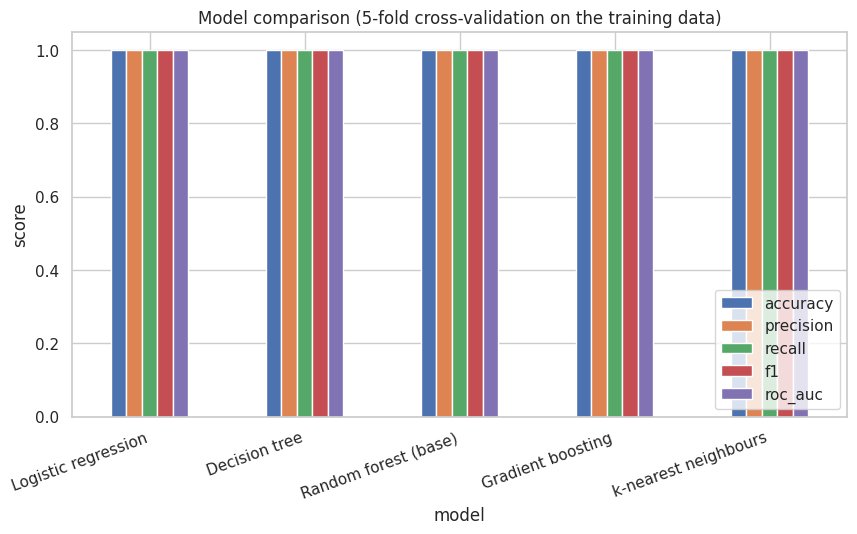

In [39]:
# Side-by-side chart of the cross-validated scores
comparison[scoring].plot(kind="bar", figsize=(10, 5), ylim=(0, 1.05))
plt.title("Model comparison (5-fold cross-validation on the training data)")
plt.ylabel("score"); plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.show()

### 6.1 Final check of every model on the unseen test set (ROC curves)

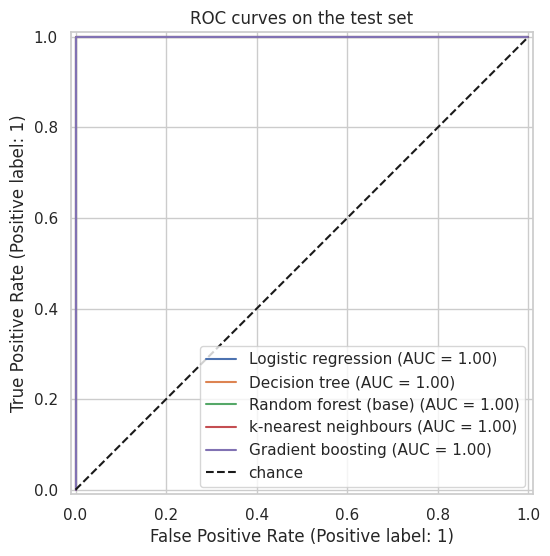

In [40]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, clf in models.items():
    pipe = make_pipe(clf).fit(X_train, y_train)
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, ax=ax, name=name)
ax.plot([0, 1], [0, 1], "k--", label="chance")
ax.set_title("ROC curves on the test set")
ax.legend(loc="lower right")
plt.show()

### 6.2 Learning curve: would more data help?

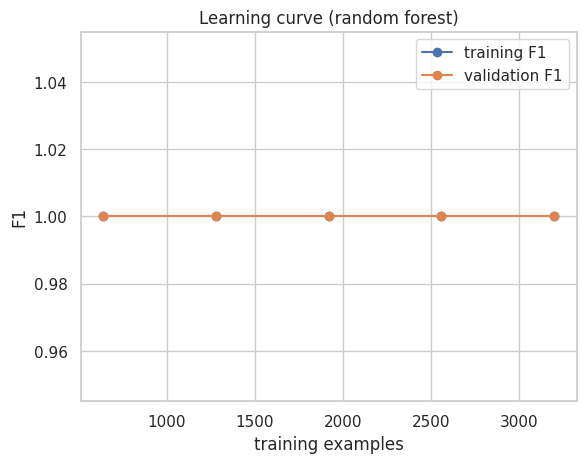

Training sizes  : [ 640 1280 1920 2560 3200]
Validation F1    : [1. 1. 1. 1. 1.]


In [41]:
# Score as the training set grows. If the validation line is still rising, more data would help.
sizes, train_sc, val_sc = learning_curve(base_model, X_train, y_train, cv=cv, scoring="f1",
                                         train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=-1)
plt.plot(sizes, train_sc.mean(axis=1), "o-", label="training F1")
plt.plot(sizes, val_sc.mean(axis=1), "o-", label="validation F1")
plt.xlabel("training examples"); plt.ylabel("F1"); plt.legend()
plt.title("Learning curve (random forest)")
plt.show()
print("Training sizes  :", sizes)
print("Validation F1    :", val_sc.mean(axis=1).round(3))

### 6.3 Other validation methods the team could add (for the final project)
- **Repeated cross-validation** or more folds, to reduce the effect of one random split.
- **Group-based splitting**, so that listings from the same seller (or, in AgroShield, the same pack or outlet) never sit on both sides of the split.
- **Confidence intervals** on the headline scores.
- **Testing on a fresh dataset** from a different source.
- **Error analysis**: look at the individual misclassified listings and ask what they have in common.

**Comparison of the models.** All five models reach F1 = 1.000 under 5-fold cross-validation, apart from k-nearest neighbours, whose recall of 0.999 (F1 standard deviation 0.001) is the only visible difference. The random forest ties for first with logistic regression, the decision tree and gradient boosting, and the difference between any two of them (0.000) is no larger than the fold-to-fold spread (`f1_std` of 0.000). A simple model (logistic regression, or a single decision tree) did exactly as well as the complex ones, so extra complexity buys nothing on this dataset. The ROC curves of all five models sit at the top-left corner (AUC = 1.0), and the learning curve is flat at F1 = 1.000 from the smallest training size (640 listings) to the largest (3,200): more data would not help because there is nothing left to learn.

**What the comparison validates.** Five different algorithms, built through the same process, agree. That shows the result of the base model does not depend on a quirk of the random forest or of one random split. It also confirms the explanation in 5.7: when every algorithm is perfect, the data are easy, not the models exceptional. This is why the comparison matters more for AgroShield's real image data, where we expect the algorithms to differ and the comparison to guide the final choice.

## 7. Link to AgroShield, limits and team contributions

**How this connects to the real project.** The AgroShield engine will follow the same workflow, with images instead of a table: collect and verify data, clean it, split it by pack and batch, fine-tune a small image model, validate it with cross-validation and a held-out test set, and compare against baselines. The conversion of the final model for Android (TensorFlow Lite) comes after this stage.


**Team contributions**

| Member | Sections they worked on | One-sentence plain-language summary |
|---|---|---|
| Moses Mugo | Sections 1 and 3 | What we predict, what the data looks like, and our 4 observations |
| Alfred Peter | Section 4 | How we cleaned the data and why, with the step table |
| Duane Makedi | Sections 5 and 6 | How we checked the model is trustworthy and how it compares with others |